# ICS 3202 Artificial Intelligence: Plant Disease Classification

**Project:** Plant disease classification for a mobile app

**Datasets:** PlantVillage, PlantDoc, Mini-ImageNet and DTD

**Approach:** Supervised learning, classifying images into 38 disease classes plus a "not a leaf" class.

**Algorithm:** CNN with transfer learning. The base model is ResNet18 pretrained on ImageNet.

Our model will run behind a mobile app, so it has to handle photos farmers take on their phones. We found two problems with training on PlantVillage alone:

1. Every PlantVillage photo shows one leaf on a plain grey background. Phone photos have soil, hands, sky and other leaves in them.
2. If the model only has disease classes, it has to give every photo a disease name, even a photo of a wall.

To deal with this, we:

- added a 39th class, `Not_a_leaf`, using everyday photos, textures and blank pictures
- added real field photos from PlantDoc
- pasted PlantVillage leaves onto random backgrounds
- used stronger augmentation (crop, zoom, lighting, colour and blur)
- report results on lab photos, field photos and non-leaf photos separately
- added a similarity check as a backup for unusual photos

Classes 0 to 37 are the PlantVillage classes in alphabetical order, and `Not_a_leaf` is class 38.

In [ ]:
# Run once.
%pip install -q torch torchvision datasets huggingface_hub pandas matplotlib pillow scikit-learn tqdm

In [ ]:
import copy
import gc
import hashlib
import os
import random
import subprocess
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from PIL import Image, ImageFilter, ImageOps
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

REPO = "mohanty/PlantVillage"
SEED = 42
MAX_EPOCHS = 12
PATIENCE = 3                  # stop after this many epochs with no improvement
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 64
NUM_WORKERS = min(4, os.cpu_count() or 1)

NOT_A_LEAF = "Not_a_leaf"
FIELD_REPEAT = 4              # field photos are few, so each one is used this many times per epoch
SEGMENTED_SHARE = 0.5         # share of segmented leaves that get pasted onto random backgrounds
PLAIN_IMAGES = 600            # generated blank, blurry or noisy pictures added to Not_a_leaf

# Everything worth keeping goes to Google Drive, so a disconnect does not lose training.
from google.colab import drive
drive.mount("/content/drive")
OUTPUT_DIR = "/content/drive/MyDrive/ResNet18_v2"
BASELINE_MODEL_PATH = "/content/drive/MyDrive/ResNet18_Base/resnet18_final.pt"   # trained on PlantVillage only, for comparison
os.makedirs(OUTPUT_DIR, exist_ok=True)

WORK_DIR = Path("/content/work")   # temporary files, rebuilt if the session resets
WORK_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_GPU = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True

print("Training device:", torch.cuda.get_device_name(0) if USE_GPU else "CPU")
if not USE_GPU:
    print("WARNING: no GPU found. Use Runtime > Change runtime type > GPU.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Training device: Tesla T4


## 1. PlantVillage

We load PlantVillage from Hugging Face (`mohanty/PlantVillage`). We use the colour photos, and also the segmented photos, which already have the background removed. We use the segmented leaves later to paste onto new backgrounds.

We hold back 10% of the colour training photos for validation. A segmented leaf is only used if its colour version is in the training part, so no validation leaf ends up in training.

In [ ]:
dataset = load_dataset(REPO, name="default")


def to_dataframe(split):
    df = pd.DataFrame({"image_path": list(split["text"])})
    parts = df["image_path"].str.split("/", n=3, expand=True)
    df["configuration"] = parts[1]
    df["class"] = parts[2]
    return df


train_all = to_dataframe(dataset["train"])
test_all = to_dataframe(dataset["test"])
print(train_all["configuration"].value_counts())

color_train = train_all[train_all["configuration"] == "color"].reset_index(drop=True)
color_test = test_all[test_all["configuration"] == "color"].reset_index(drop=True)
segmented_all = train_all[train_all["configuration"] == "segmented"].reset_index(drop=True)
del dataset, train_all, test_all

archive_path = hf_hub_download(repo_id=REPO, filename="data.zip", repo_type="dataset")

leaf_classes = sorted(color_train["class"].unique())
assert len(leaf_classes) == 38
class_names = leaf_classes + [NOT_A_LEAF]      # Not_a_leaf last: classes 0-37 stay in alphabetical order
class_to_index = {name: index for index, name in enumerate(class_names)}
NOT_A_LEAF_ID = class_to_index[NOT_A_LEAF]

pv_train, pv_val = train_test_split(
    color_train, test_size=0.10, stratify=color_train["class"], random_state=SEED)


def leaf_key(path):
    """The same key for a colour photo and its segmented copy."""
    cls, name = path.split("/")[2], Path(path).stem.lower()
    return cls + "/" + name.replace("_final_masked", "")


train_keys = set(pv_train["image_path"].map(leaf_key))
segmented_train = segmented_all[segmented_all["image_path"].map(leaf_key).isin(train_keys)]
segmented_train = segmented_train.sample(frac=SEGMENTED_SHARE, random_state=SEED)

print(f"\nLab photos: {len(pv_train):,} train, {len(pv_val):,} validation, {len(color_test):,} test")
print(f"Segmented leaves used for pasting: {len(segmented_train):,}")
if len(segmented_train) == 0:
    print("WARNING: no segmented photos matched. Training continues without pasted backgrounds.")

README.md:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

grayscale_train.txt:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

segmented_train.txt:   0%|          | 0.00/4.86M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

grayscale_test.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

... (2 outputs left out)

Generating test split: 0 examples [00:00, ? examples/s]

configuration
color        43596
grayscale    43203
segmented    42984
Name: count, dtype: int64


data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]


Lab photos: 39,236 train, 4,360 validation, 10,709 test
Segmented leaves used for pasting: 15,181


## 2. Field photos (PlantDoc)

PlantDoc has about 2,600 leaf photos taken in real conditions, with its own train and test split. Its class names are different from PlantVillage's, so we mapped each PlantDoc folder to the matching PlantVillage class. PlantDoc has no photos for 9 of our classes, such as Orange Huanglongbing and Tomato Target Spot.

We shrink the photos to at most 512 pixels once, so training does not have to open large photos every epoch. PlantDoc has some repeated photos, so we remove any test photo that also appears in train.

We hold back 15% of the PlantDoc train photos for validation.

In [ ]:
FIELD_DIR = Path("/content/PlantDoc-Dataset")
if not FIELD_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/pratikkayal/PlantDoc-Dataset", str(FIELD_DIR)], check=True)

PLANTDOC_TO_PLANTVILLAGE = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Peach leaf": "Peach___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}
assert set(PLANTDOC_TO_PLANTVILLAGE.values()) <= set(leaf_classes)

FIELD_CACHE = WORK_DIR / "field"


def load_field(split):
    rows, skipped = [], Counter()
    for folder in sorted((FIELD_DIR / split).iterdir()):
        if not folder.is_dir():
            continue
        cls = PLANTDOC_TO_PLANTVILLAGE.get(folder.name)
        if cls is None:
            skipped[f"unmapped folder: {folder.name}"] += 1
            continue
        for file in sorted(folder.iterdir()):
            target = FIELD_CACHE / split / folder.name / (file.name + ".jpg")
            if not target.exists():
                try:
                    with Image.open(file) as image:
                        image = ImageOps.exif_transpose(image).convert("RGB")
                        image.thumbnail((512, 512))
                        target.parent.mkdir(parents=True, exist_ok=True)
                        image.save(target, quality=95)
                except Exception:
                    skipped["unreadable file"] += 1
                    continue
            rows.append({"image_path": str(target), "class": cls,
                         "hash": hashlib.md5(file.read_bytes()).hexdigest()})
    if skipped:
        print(split, "skipped:", dict(skipped))
    return pd.DataFrame(rows).drop_duplicates("hash").reset_index(drop=True)


field_train_all = load_field("train")
field_test = load_field("test")
before = len(field_test)
field_test = field_test[~field_test["hash"].isin(field_train_all["hash"])].reset_index(drop=True)
print(f"Removed {before - len(field_test)} test photos that also appear in train")

try:
    field_train, field_val = train_test_split(
        field_train_all, test_size=0.15, stratify=field_train_all["class"], random_state=SEED)
except ValueError:   # a class too small to split evenly
    field_train, field_val = train_test_split(field_train_all, test_size=0.15, random_state=SEED)

print(f"Field photos: {len(field_train):,} train, {len(field_val):,} validation, {len(field_test):,} test")
display(field_train_all["class"].value_counts().rename("photos").to_frame())

Removed 11 test photos that also appear in train
Field photos: 1,989 train, 352 validation, 225 test


,photos
class,
Corn_(maize)___Northern_Leaf_Blight,180
Tomato___Septoria_leaf_spot,140
Squash___Powdery_mildew,124
Raspberry___healthy,112
Potato___Early_blight,109
Corn_(maize)___Common_rust_,106
Blueberry___healthy,106
Peach___healthy,103
Tomato___Bacterial_spot,101


## 3. Not-a-leaf photos

For the `Not_a_leaf` class we use:

- **Everyday photos:** the Mini-ImageNet test split, 5,000 photos of 100 kinds of things. We left out ladybugs and ears of corn, since those photos usually have leaves in them.
- **Textures:** the DTD test split, with surfaces like cracked, bumpy and stained, which look like soil, walls and fabric. We left out "veined", since many of those are leaf close-ups.
- **Plain pictures:** blank, blurry and noisy images we generate, like a covered lens or an accidental photo.

We split them 70% train, 10% validation and 20% test. The training part is also used as backgroundss for the pasted leaves.

In [ ]:
imagenet = load_dataset("timm/mini-imagenet", data_files={"test": "data/test-*.parquet"},
                        split="test", verification_mode="no_checks")
textures = load_dataset("tanganke/dtd", data_files={"test": "data/test-*.parquet"},
                        split="test", verification_mode="no_checks")

IMAGENET_SKIP = {29, 99}   # 29 = ladybug (usually on a leaf), 99 = ear of corn
TEXTURE_SKIP = {42}        # 42 = veined (often a leaf close-up)


def make_plain(seed, size=256):
    """A generated non-leaf picture: flat colour, gradient or noise, sometimes blurred."""
    rng = np.random.default_rng(seed)
    kind = seed % 3
    if kind == 0:
        array = np.ones((size, size, 3)) * rng.integers(0, 256, 3)
    elif kind == 1:
        ramp = np.linspace(0, 1, size)[:, None, None]
        array = rng.integers(0, 256, 3) * (1 - ramp) + rng.integers(0, 256, 3) * ramp
        array = np.repeat(array, size, axis=1)
    else:
        array = rng.normal(rng.integers(40, 216), rng.integers(10, 60), (size, size, 3))
    image = Image.fromarray(np.clip(array, 0, 255).astype(np.uint8))
    return image.filter(ImageFilter.GaussianBlur(int(rng.integers(0, 6))))


not_leaf = pd.DataFrame(
    [("imagenet", i) for i, label in enumerate(imagenet["label"]) if label not in IMAGENET_SKIP]
    + [("texture", i) for i, label in enumerate(textures["label"]) if label not in TEXTURE_SKIP]
    + [("plain", i) for i in range(PLAIN_IMAGES)],
    columns=["source", "ref"],
)
not_leaf = not_leaf.sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(not_leaf)
not_leaf_train = not_leaf.iloc[: int(n * 0.7)]
not_leaf_val = not_leaf.iloc[int(n * 0.7): int(n * 0.8)]
not_leaf_test = not_leaf.iloc[int(n * 0.8):]
print(f"Not-a-leaf photos: {len(not_leaf_train):,} train, {len(not_leaf_val):,} validation, {len(not_leaf_test):,} test")
print(not_leaf["source"].value_counts().to_string())

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  326MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  336MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/2.85k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  179MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/1880 [00:00<?, ? examples/s]

Not-a-leaf photos: 5,138 train, 734 validation, 1,468 test
source
imagenet    4900
texture     1840
plain        600


### Dataset summary

Number of images from each source in each split. The train count for field photos is before they are repeated.

In [ ]:
summary = pd.DataFrame({
    "Lab photos (PlantVillage colour)": [len(pv_train), len(pv_val), len(color_test)],
    "Lab leaves pasted on backgrounds": [len(segmented_train), 0, 0],
    "Field photos (PlantDoc)": [len(field_train), len(field_val), len(field_test)],
    "Not a leaf": [len(not_leaf_train), len(not_leaf_val), len(not_leaf_test)],
}, index=["Train", "Validation", "Test"]).T
summary["Total"] = summary.sum(axis=1)
display(summary)

,Train,Validation,Test,Total
Lab photos (PlantVillage colour),39236,4360,10709,54305
Lab leaves pasted on backgrounds,15181,0,0,15181
Field photos (PlantDoc),1989,352,225,2566
Not a leaf,5138,734,1468,7340


## 4. Prepare the images

We put all the images into one table that records where each image comes from and its class.

**Pasting leaves onto backgrounds.** In a segmented photo, every pixel that is not black is part of the leaf. We resize the leaf and paste it at a random spot on a random not-a-leaf training photo or plain picture. The label stays the leaf's disease, so the model learns to look at the leaf and not the background.

**Augmentation** for training images:
- random crop and zoom (keeps 35% to 100% of the photo)
- flips and rotations up to 20°
- changes to brightness, contrast, saturation and hue
- occasional blur

Validation and test images are only resized to 224 × 224 and normalised with ImageNet values, the same as the app's server does with uploaded photos.

Training rows by source:
source
zip         39236
paste       15181
file         7956
imagenet     3414
texture      1304
plain         420
Total: 67,511


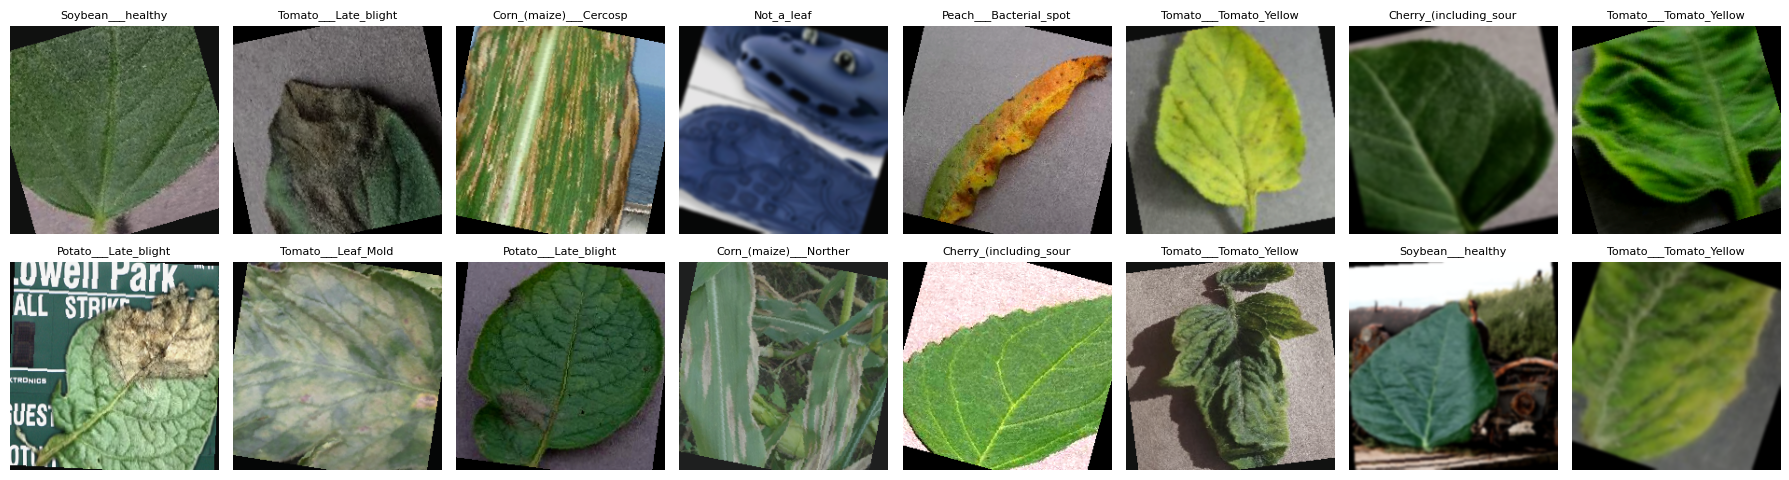

In [ ]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.35, 1.0), ratio=(0.75, 1.33)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.35, contrast=0.35, saturation=0.3, hue=0.03),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=7, sigma=(0.1, 2.5))], p=0.25),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def table(df, source):
    """Turn a list of photos into rows of (source, ref, label). source=None means not-a-leaf rows."""
    if source is None:
        return pd.DataFrame({"source": df["source"], "ref": df["ref"], "label": NOT_A_LEAF_ID})
    return pd.DataFrame({"source": source, "ref": df["image_path"],
                         "label": df["class"].map(class_to_index)})


train_table = pd.concat([
    table(pv_train, "zip"),
    table(segmented_train, "paste"),
    *[table(field_train, "file")] * FIELD_REPEAT,
    table(not_leaf_train, None),
], ignore_index=True)

val_tables = {
    "lab": table(pv_val, "zip"),
    "field": table(field_val, "file"),
    "not_leaf": table(not_leaf_val, None),
}
test_tables = {
    "lab": table(color_test, "zip"),
    "field": table(field_test, "file"),
    "not_leaf": table(not_leaf_test, None),
}

BACKGROUNDS = list(not_leaf_train[not_leaf_train["source"] != "plain"].itertuples(index=False, name=None))

print("Training rows by source:")
print(train_table["source"].value_counts().to_string())
print(f"Total: {len(train_table):,}")


def paste_on_background(leaf, background, size=256):
    background = ImageOps.fit(background, (size, size))
    mask = (leaf.convert("L").point(lambda v: 255 if v > 15 else 0)
            .filter(ImageFilter.MedianFilter(5)).filter(ImageFilter.GaussianBlur(1.5)))
    leaf_size = int(size * random.uniform(0.55, 1.0))
    leaf, mask = leaf.resize((leaf_size, leaf_size)), mask.resize((leaf_size, leaf_size))
    x, y = random.randint(0, size - leaf_size), random.randint(0, size - leaf_size)
    background.paste(leaf, (x, y), mask)
    return background


class MixedImages(Dataset):
    def __init__(self, rows, transform):
        self.sources = rows["source"].tolist()
        self.refs = rows["ref"].tolist()
        self.labels = rows["label"].to_numpy()
        self.transform = transform
        self.archive = None   # opened inside each worker, as they cannot share one handle

    def __len__(self):
        return len(self.labels)

    def load(self, source, ref):
        if source in ("zip", "paste"):
            if self.archive is None:
                self.archive = zipfile.ZipFile(archive_path)
            with self.archive.open(ref) as file:
                image = Image.open(file).convert("RGB")
            if source == "paste":
                if random.random() < 0.2:
                    background = make_plain(random.randrange(10**6))
                else:
                    background = self.load(*random.choice(BACKGROUNDS))
                image = paste_on_background(image, background)
            return image
        if source == "file":
            with Image.open(ref) as image:
                return image.convert("RGB")
        if source == "imagenet":
            return imagenet[int(ref)]["image"].convert("RGB")
        if source == "texture":
            return textures[int(ref)]["image"].convert("RGB")
        if source == "plain":
            return make_plain(int(ref))
        raise ValueError(source)

    def __getitem__(self, index):
        image = self.load(self.sources[index], self.refs[index])
        return self.transform(image), int(self.labels[index])


def make_loader(rows, transform, shuffle=False):
    return DataLoader(
        MixedImages(rows, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=NUM_WORKERS, pin_memory=USE_GPU, persistent_workers=NUM_WORKERS > 0,
    )


# Look at some training images before the long run, to check the pasting and changes look sensible.
preview = MixedImages(train_table.sample(16, random_state=SEED), train_transform)
figure, axes = plt.subplots(2, 8, figsize=(18, 5))
for axis, i in zip(axes.flat, range(16)):
    image, label = preview[i]
    image = image.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN
    axis.imshow(np.clip(image, 0, 1))
    axis.set_title(class_names[label][:22], fontsize=8)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Model

ResNet18 starts with weights learned from ImageNet. We replace its last layer with one that has 39 outputs, then train the whole network.

- **Class-weighted loss:** mistakes on small classes count for more.
- **AdamW:** the learning rate is 0.0001, with weight decay to reduce overfitting. A cosine schedule lowers the learning rate slowly during training.
- **Mixed precision:** makes training faster on the GPU.
- **Choosing the best epoch:** we use the average of three scores: macro-F1 on lab photos, macro-F1 on field photos, and how well the model separates leaves from non-leaves. We did not use lab photos alone, because a model can do very well on them and still fail on real photos.

In [ ]:
def create_resnet18(pretrained=True, num_classes=len(class_names)):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def create_loss(labels):
    counts = np.bincount(labels, minlength=len(class_names))
    weights = len(labels) / (len(class_names) * np.maximum(counts, 1))
    return nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))


def train_one_epoch(model, loader, loss_function, optimizer, scaler):
    model.train()
    total_loss = 0.0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_GPU):
            loss = loss_function(model(images), labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)


def features(model, images):
    """The 512 numbers ResNet18 produces just before its last layer."""
    x = model.maxpool(model.relu(model.bn1(model.conv1(images))))
    x = model.layer4(model.layer3(model.layer2(model.layer1(x))))
    return torch.flatten(model.avgpool(x), 1)


def run(model, rows):
    """Return labels, predictions, confidences and normalised 512-number summaries."""
    model.eval()
    predictions, confidences, summaries = [], [], []
    with torch.inference_mode():
        for images, _ in make_loader(rows, eval_transform):
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_GPU):
                summary = features(model, images)
                logits = model.fc(summary)
            probabilities = torch.softmax(logits.float(), dim=1)
            confidence, prediction = probabilities.max(dim=1)
            predictions.append(prediction.cpu())
            confidences.append(confidence.cpu())
            summaries.append(F.normalize(summary.float(), dim=1).cpu())
    return (rows["label"].to_numpy(), torch.cat(predictions).numpy(),
            torch.cat(confidences).numpy(), torch.cat(summaries))


def macro_f1(labels, predictions):
    return f1_score(labels, predictions, labels=sorted(set(labels)), average="macro", zero_division=0)


def score(model, tables):
    lab_y, lab_p, _, _ = run(model, tables["lab"])
    field_y, field_p, _, _ = run(model, tables["field"])
    _, not_leaf_p, _, _ = run(model, tables["not_leaf"])
    leaves_kept = np.mean(np.concatenate([lab_p, field_p]) != NOT_A_LEAF_ID)
    not_leaf_rejected = np.mean(not_leaf_p == NOT_A_LEAF_ID)
    result = {
        "lab_macro_f1": macro_f1(lab_y, lab_p),
        "field_macro_f1": macro_f1(field_y, field_p),
        "field_accuracy": accuracy_score(field_y, field_p),
        "leaves_kept": leaves_kept,
        "not_leaf_rejected": not_leaf_rejected,
    }
    result["score"] = np.mean([result["lab_macro_f1"], result["field_macro_f1"],
                               (leaves_kept + not_leaf_rejected) / 2])
    return result


def free_memory():
    gc.collect()
    if USE_GPU:
        torch.cuda.empty_cache()

## 6. Training

We train once on all the training images and check the validation sets after every epoch. The best epoch is saved as `resnet18_v2.pt`. Training stops early if the score does not improve for 3 epochs.

We save a checkpoint to Google Drive after every epoch, so if the Colab session ends, training continues from the last finished epoch.

In [ ]:
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "checkpoint.pt")
BEST_PATH = os.path.join(OUTPUT_DIR, "resnet18_v2.pt")

set_seed(SEED)
train_loader = make_loader(train_table, train_transform, shuffle=True)
model = create_resnet18().to(DEVICE)
loss_function = create_loss(train_table["label"].to_numpy())
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_GPU)
start_epoch, best_score, best_epoch, history = 1, -1.0, 0, []

if os.path.exists(CHECKPOINT_PATH):
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    scaler.load_state_dict(checkpoint["scaler"])
    start_epoch = checkpoint["epoch"] + 1
    best_score, best_epoch, history = checkpoint["best_score"], checkpoint["best_epoch"], checkpoint["history"]
    print(f"Resuming after epoch {checkpoint['epoch']} (best so far: epoch {best_epoch})")

for epoch in range(start_epoch, MAX_EPOCHS + 1):
    if epoch - best_epoch > PATIENCE:
        print("Already stopped early in an earlier session.")
        break
    start = time.perf_counter()
    train_loss = train_one_epoch(model, train_loader, loss_function, optimizer, scaler)
    scheduler.step()
    result = score(model, val_tables)
    history.append({"epoch": epoch, "train_loss": train_loss, **result})
    print(f"Epoch {epoch}/{MAX_EPOCHS} | loss {train_loss:.4f} | lab F1 {result['lab_macro_f1']:.4f} | "
          f"field F1 {result['field_macro_f1']:.4f} | not-leaf rejected {result['not_leaf_rejected']:.3f} | "
          f"leaves kept {result['leaves_kept']:.3f} | {time.perf_counter() - start:.0f}s")

    if result["score"] > best_score:
        best_score, best_epoch = result["score"], epoch
        torch.save(model.state_dict(), BEST_PATH)
        print("  saved as best")

    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                "best_score": best_score, "best_epoch": best_epoch, "history": history}, CHECKPOINT_PATH)

    if epoch - best_epoch >= PATIENCE:
        print("Stopping early: no improvement.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(os.path.join(OUTPUT_DIR, "history.csv"), index=False)
display(history_df.round(4))
print("Best epoch:", best_epoch)

del train_loader, optimizer, scheduler, scaler, loss_function
free_memory()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]


Resuming after epoch 5 (best so far: epoch 5)


Training:   0%|          | 0/1055 [00:00<?, ?it/s]

Epoch 6/12 | loss 0.0963 | lab F1 0.9895 | field F1 0.6296 | not-leaf rejected 0.989 | leaves kept 0.999 | 858s
  saved as best


Training:   0%|          | 0/1055 [00:00<?, ?it/s]

... (9 outputs left out)

Training:   0%|          | 0/1055 [00:00<?, ?it/s]

Epoch 12/12 | loss 0.0549 | lab F1 0.9925 | field F1 0.6416 | not-leaf rejected 0.986 | leaves kept 0.999 | 862s
Stopping early: no improvement.


,epoch,train_loss,lab_macro_f1,field_macro_f1,field_accuracy,leaves_kept,not_leaf_rejected,score
0,1,0.7082,0.9586,0.4816,0.5057,0.9989,0.9673,0.8078
1,2,0.3146,0.9645,0.5344,0.5426,1.0000,0.9564,0.8257
2,3,0.2417,0.9765,0.5378,0.5483,0.9989,0.9823,0.8350
3,4,0.1916,0.9733,0.5740,0.5881,0.9994,0.9864,0.8467
4,5,0.1584,0.9867,0.6019,0.6193,0.9998,0.9809,0.8597
5,6,0.0963,0.9895,0.6296,0.6364,0.9985,0.9891,0.8710
6,7,0.0616,0.9872,0.6356,0.6477,0.9996,0.9687,0.8690
7,8,0.0455,0.9918,0.6232,0.6364,0.9992,0.9905,0.8699
8,9,0.0327,0.9913,0.6535,0.6619,0.9996,0.9864,0.8793
9,10,0.0245,0.9929,0.6472,0.6534,0.9992,0.9932,0.8788


Best epoch: 9


## 7. Test

We test the best model once on three test sets that were not used for training or for choosing the epoch:

- **Lab photos:** the PlantVillage test set.
- **Field photos:** the PlantDoc test set. These are the closest to what farmers will upload.
- **Not-a-leaf photos:** we check how many are rejected.

We also test a baseline on the same sets: a ResNet18 we trained on PlantVillage colour photos only, with 38 classes. It has no "not a leaf" class, so for the baseline we count a photo as rejected when its confidence is below 0.8.

In [ ]:
model = create_resnet18(pretrained=False).to(DEVICE)
model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=True))

test_results = {name: run(model, rows) for name, rows in test_tables.items()}
rows = []
for name in ("lab", "field"):
    y, p, _, _ = test_results[name]
    rows.append({"model": "Final model", "test set": name, "accuracy": accuracy_score(y, p),
                 "macro_f1": macro_f1(y, p), "wrongly rejected": np.mean(p == NOT_A_LEAF_ID)})
rows.append({"model": "Final model", "test set": "not_leaf",
             "rejected": np.mean(test_results["not_leaf"][1] == NOT_A_LEAF_ID)})

if os.path.exists(BASELINE_MODEL_PATH):
    baseline = create_resnet18(pretrained=False, num_classes=38).to(DEVICE)
    baseline.load_state_dict(torch.load(BASELINE_MODEL_PATH, map_location=DEVICE, weights_only=True))
    for name, table_rows in test_tables.items():
        y, p, confidence, _ = run(baseline, table_rows)
        if name == "not_leaf":
            rows.append({"model": "Baseline", "test set": name, "rejected": np.mean(confidence < 0.8)})
        else:
            rows.append({"model": "Baseline", "test set": name, "accuracy": accuracy_score(y, p),
                         "macro_f1": macro_f1(y, p), "wrongly rejected": np.mean(confidence < 0.8)})
    del baseline
    free_memory()
else:
    print("Baseline model not found at", BASELINE_MODEL_PATH, "- skipping the comparison")

results_df = pd.DataFrame(rows)
results_df.to_csv(os.path.join(OUTPUT_DIR, "test_results.csv"), index=False)
display(results_df.round(4))

y, p, _, _ = test_results["field"]
present = sorted(set(y))
report = pd.DataFrame(classification_report(
    y, p, labels=present, target_names=[class_names[i] for i in present],
    output_dict=True, zero_division=0)).T
print("\nWeakest classes on field photos:")
display(report.loc[[class_names[i] for i in present]].sort_values("f1-score").head(8).round(3))

,model,test set,accuracy,macro_f1,wrongly rejected,rejected
0,Final model,lab,0.9908,0.9885,0.0002,NaN
1,Final model,field,0.6756,0.6625,0.0089,NaN
2,Final model,not_leaf,NaN,NaN,NaN,0.9898
3,Baseline,lab,0.9909,0.9893,0.0147,NaN
4,Baseline,field,0.1733,0.1948,0.4933,NaN
5,Baseline,not_leaf,NaN,NaN,NaN,0.5531



Weakest classes on field photos:


,precision,recall,f1-score,support
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.200,0.333,0.250,3.0
Potato___Early_blight,0.286,0.286,0.286,7.0
Tomato___Tomato_mosaic_virus,0.667,0.200,0.308,10.0
Tomato___Early_blight,0.600,0.333,0.429,9.0
Tomato___Leaf_Mold,0.500,0.500,0.500,6.0
Corn_(maize)___Northern_Leaf_Blight,0.556,0.500,0.526,10.0
Tomato___Bacterial_spot,0.500,0.625,0.556,8.0
Potato___Late_blight,0.500,0.800,0.615,5.0


## 8. Similarity check

The `Not_a_leaf` class only knows the kinds of photos we showed it, so we added a second check.

For each of the 38 leaf classes, we take the average of the 512 features ResNet18 produces before its last layer, over that class's training photos. For a new photo, we compare its features with the average for the class it was given, using cosine similarity. If the photo is too different, the app asks for a new photo instead of naming a disease.

We set the cut-off so that about 98% of real validation leaves pass, for lab and field photos separately, and use the lower of the two.

The class averages and the cut-off are saved in `resnet18_v2_check.pt`.

In [ ]:
reference = pv_train.groupby("class", group_keys=False).apply(
    lambda g: g.sample(min(len(g), 150), random_state=SEED))
reference_rows = pd.concat([table(reference, "zip"), table(field_train, "file")], ignore_index=True)
labels, _, _, summaries = run(model, reference_rows)

centroids = torch.zeros(38, summaries.shape[1])
for class_id in range(38):
    centroids[class_id] = summaries[torch.from_numpy(labels == class_id)].mean(dim=0)
centroids = F.normalize(centroids, dim=1)


def similarity(predictions, summaries):
    """Cosine similarity between each photo and the average photo of its predicted class."""
    leaf = predictions != NOT_A_LEAF_ID
    result = np.full(len(predictions), -1.0)
    leaf_ids = torch.from_numpy(predictions[leaf]).long()
    result[leaf] = (summaries[torch.from_numpy(leaf)] * centroids[leaf_ids]).sum(dim=1).numpy()
    return result


cutoffs = []
for name in ("lab", "field"):
    _, p, _, s = run(model, val_tables[name])
    similarities = similarity(p, s)
    cutoffs.append(np.quantile(similarities[p != NOT_A_LEAF_ID], 0.02))
threshold = float(min(cutoffs))
print(f"Cut-offs (lab, field): {cutoffs[0]:.3f}, {cutoffs[1]:.3f}. Using {threshold:.3f}")

print("\nOn the test sets, with Not_a_leaf and the similarity check together:")
with_check = {}
for name, (y, p, _, s) in test_results.items():
    rejected = (p == NOT_A_LEAF_ID) | (similarity(p, s) < threshold)
    kept = ~rejected
    with_check[name] = {"rejected": rejected.mean(),
                        "accuracy_kept": accuracy_score(y[kept], p[kept]) if kept.any() else np.nan}
    if name == "not_leaf":
        print(f"  not-a-leaf photos rejected: {rejected.mean():.3f}")
    else:
        print(f"  {name}: wrongly rejected {rejected.mean():.3f}, "
              f"accuracy on the photos kept {with_check[name]['accuracy_kept']:.4f}")

torch.save({"centroids": centroids, "threshold": threshold, "class_names": class_names},
           os.path.join(OUTPUT_DIR, "resnet18_v2_check.pt"))
print("\nSaved", os.path.join(OUTPUT_DIR, "resnet18_v2_check.pt"))

/tmp/ipykernel_663/3986849541.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reference = pv_train.groupby("class", group_keys=False).apply(


Cut-offs (lab, field): 0.841, 0.688. Using 0.688

On the test sets, with Not_a_leaf and the similarity check together:
  lab: wrongly rejected 0.000, accuracy on the photos kept 0.9911
  field: wrongly rejected 0.044, accuracy on the photos kept 0.7023
  not-a-leaf photos rejected: 0.993

Saved /content/drive/MyDrive/ResNet18_v2/resnet18_v2_check.pt


## 9. Results

The table and summary below come from the test results in sections 7 and 8. We also save them to `results.md`.

We expected the baseline to score a little higher on lab photos, since that is all it was trained on. Field photos and non-leaf photos matter more for our app.

In [ ]:
from IPython.display import Markdown


def value(model, test_set, measure):
    match = results_df[(results_df["model"] == model) & (results_df["test set"] == test_set)]
    if match.empty or measure not in match or pd.isna(match[measure].iloc[0]):
        return None
    return float(match[measure].iloc[0])


def pct(number):
    return "n/a" if number is None or pd.isna(number) else f"{number * 100:.2f}%"


has_baseline = (results_df["model"] == "Baseline").any()
lines = [
    "| Test set | Measure | " + ("Baseline (PlantVillage only) | " if has_baseline else "") + "Final model | Final model + similarity check |",
    "|---|---|" + ("---|" if has_baseline else "") + "---|---|",
]
table_rows = [
    ("Lab photos (PlantVillage)", "lab", "accuracy", "Accuracy"),
    ("Lab photos (PlantVillage)", "lab", "macro_f1", "Macro-F1"),
    ("Field photos (PlantDoc)", "field", "accuracy", "Accuracy"),
    ("Field photos (PlantDoc)", "field", "macro_f1", "Macro-F1"),
    ("Field photos (PlantDoc)", "field", "wrongly rejected", "Real leaves wrongly rejected"),
    ("Not-a-leaf photos", "not_leaf", "rejected", "Correctly rejected"),
]
for label, test_set, measure, measure_name in table_rows:
    if measure == "rejected":
        checked = with_check[test_set]["rejected"]
    elif measure == "wrongly rejected":
        checked = with_check[test_set]["rejected"]
    elif measure == "accuracy":
        checked = with_check[test_set]["accuracy_kept"]
    else:
        checked = None
    cells = [label, measure_name]
    if has_baseline:
        cells.append(pct(value("Baseline", test_set, measure)))
    cells += [pct(value("Final model", test_set, measure)), pct(checked)]
    lines.append("| " + " | ".join(cells) + " |")

lines.append("")
lines.append("With the similarity check, accuracy is measured on the photos that pass the check.")
lines.append("")

field_acc = value("Final model", "field", "accuracy")
field_f1 = value("Final model", "field", "macro_f1")
lab_acc = value("Final model", "lab", "accuracy")
not_leaf_rejected = value("Final model", "not_leaf", "rejected")

summary = []
if has_baseline:
    base_field = value("Baseline", "field", "accuracy")
    base_lab = value("Baseline", "lab", "accuracy")
    base_not_leaf = value("Baseline", "not_leaf", "rejected")
    direction = "higher" if field_acc >= base_field else "lower"
    summary.append(
        f"On field photos, the final model reached {pct(field_acc)} accuracy and {pct(field_f1)} macro-F1, "
        f"{abs(field_acc - base_field) * 100:.1f} points {direction} than the baseline's {pct(base_field)}.")
    summary.append(
        f"It rejected {pct(not_leaf_rejected)} of the photos that are not leaves, or "
        f"{pct(with_check['not_leaf']['rejected'])} with the similarity check. The baseline rejected "
        f"{pct(base_not_leaf)} using a confidence cut-off of 0.8, and gave a disease name to the rest.")
    change = (lab_acc - base_lab) * 100
    summary.append(
        f"On lab photos it scored {pct(lab_acc)} accuracy, {abs(change):.1f} points "
        f"{'above' if change >= 0 else 'below'} the baseline's {pct(base_lab)}.")
else:
    summary.append(
        f"On field photos, the final model reached {pct(field_acc)} accuracy and {pct(field_f1)} macro-F1. "
        f"It rejected {pct(not_leaf_rejected)} of the photos that are not leaves "
        f"({pct(with_check['not_leaf']['rejected'])} with the similarity check), "
        f"and scored {pct(lab_acc)} accuracy on lab photos.")

weakest = report.loc[[class_names[i] for i in present]].sort_values("f1-score").head(3)
weak = [f"{name.replace('___', ' ').replace('_', ' ').strip()} ({row['f1-score'] * 100:.1f}% F1)"
        for name, row in weakest.iterrows()]
summary.append("The weakest classes on field photos were "
               + (", ".join(weak[:-1]) + " and " + weak[-1] if len(weak) > 1 else weak[0]) + ".")

results_markdown = "\n".join(lines) + "\n" + " ".join(summary)
with open(os.path.join(OUTPUT_DIR, "results.md"), "w") as file:
    file.write(results_markdown)
display(Markdown(results_markdown))

| Test set | Measure | Baseline (PlantVillage only) | Final model | Final model + similarity check |
|---|---|---|---|---|
| Lab photos (PlantVillage) | Accuracy | 99.09% | 99.08% | 99.11% |
| Lab photos (PlantVillage) | Macro-F1 | 98.93% | 98.85% | n/a |
| Field photos (PlantDoc) | Accuracy | 17.33% | 67.56% | 70.23% |
| Field photos (PlantDoc) | Macro-F1 | 19.48% | 66.25% | n/a |
| Field photos (PlantDoc) | Real leaves wrongly rejected | 49.33% | 0.89% | 4.44% |
| Not-a-leaf photos | Correctly rejected | 55.31% | 98.98% | 99.25% |

With the similarity check, accuracy is measured on the photos that pass the check.

On field photos, the final model reached 67.56% accuracy and 66.25% macro-F1, 50.2 points higher than the baseline's 17.33%. It rejected 98.98% of the photos that are not leaves, or 99.25% with the similarity check. The baseline rejected 55.31% using a confidence cut-off of 0.8, and gave a disease name to the rest. On lab photos it scored 99.08% accuracy, 0.0 points below the baseline's 99.09%. The weakest classes on field photos were Corn (maize) Cercospora leaf spot Gray leaf spot (25.0% F1), Potato Early blight (28.6% F1) and Tomato Tomato mosaic virus (30.8% F1).

## 10. Using the model in the app

The app's server loads two files:

- `resnet18_v2.pt`: the model (39 classes)
- `resnet18_v2_check.pt`: the class averages and cut-off for the similarity check

For each photo, the server returns the disease. If the model says `Not_a_leaf` or the similarity check fails, it asks the user to take the photo again.

## 11. Limitations

1. **Few field photos.** PlantDoc has about 2,500 photos across 28 classes, and none for 9 of our classes. For those 9 classes the model has only seen lab photos.
2. **PlantDoc labels are not perfect.** Its photos come from the internet, and some are labelled wrongly or show more than one leaf.
3. **`Not_a_leaf` cannot cover everything.** It only knows the kinds of photos we showed it. The similarity check helps, but does not catch everything.
4. **Only PlantVillage crops.** Crops like cassava and beans are not in the dataset, so photos of them are either rejected or given the wrong class.
5. **No cross-validation.** To save GPU time we used one validation split, so we have no spread of scores across folds.

## References

- Hughes, D. P., & Salathé, M. (2015). *An open access repository of images on plant health to enable the development of mobile disease diagnostics.* arXiv:1511.08060. (PlantVillage)
- Mohanty, S. P., Hughes, D. P., & Salathé, M. (2016). *Using deep learning for image-based plant disease detection.* Frontiers in Plant Science, 7, 1419.
- Singh, D., Jain, N., Jain, P., Kayal, P., Kumawat, S., & Batra, N. (2020). *PlantDoc: A dataset for visual plant disease detection.* Proceedings of the 7th ACM IKDD CoDS and 25th COMAD, 249–253.
- Russakovsky, O., et al. (2015). *ImageNet large scale visual recognition challenge.* International Journal of Computer Vision, 115(3), 211–252. (Mini-ImageNet is a 100-class subset.)
- Cimpoi, M., Maji, S., Kokkinos, I., Mohamed, S., & Vedaldi, A. (2014). *Describing textures in the wild.* CVPR. (DTD)
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). *Deep residual learning for image recognition.* CVPR. (ResNet)